<a href="https://colab.research.google.com/github/Lekhana-Y/ML/blob/main/PCA_ml_l6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Import and load the dataset

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
food = pd.read_csv("food-texture.csv", index_col=0)

print(food.head())
print("\nShape:", food.shape)
print("\nColumns:", food.columns.tolist())

       Oil  Density  Crispy  Fracture  Hardness
B110  16.5     2955      10        23        97
B136  17.7     2660      14         9       139
B171  16.2     2870      12        17       143
B192  16.7     2920      10        31        95
B225  16.3     2975      11        26       143

Shape: (50, 5)

Columns: ['Oil', 'Density', 'Crispy', 'Fracture', 'Hardness']


Check the raw data

In [ ]:
print(food.describe())

             Oil     Density     Crispy   Fracture    Hardness
count  50.000000    50.00000  50.000000  50.000000   50.000000
mean   17.202000  2857.60000  11.520000  20.860000  128.180000
std     1.592007   124.49998   1.775571   5.466073   31.127578
min    13.700000  2570.00000   7.000000   9.000000   63.000000
25%    16.300000  2772.50000  10.000000  17.000000  107.250000
50%    16.900000  2867.50000  12.000000  21.000000  126.000000
75%    18.100000  2945.00000  13.000000  25.000000  143.750000
max    21.200000  3125.00000  15.000000  33.000000  192.000000


Center and scale the data

The example uses autoscaling:

Z=
s
X−
X
ˉ
	​


In [ ]:

scaler = StandardScaler()

X_scaled = scaler.fit_transform(food)

scaled_food = pd.DataFrame(
    X_scaled,
    columns=food.columns,
    index=food.index
)

print(scaled_food.head())

print("Means:")
print(scaled_food.mean())

print("\nStandard deviations:")
print(scaled_food.std())

           Oil   Density    Crispy  Fracture  Hardness
B110 -0.445430  0.790272 -0.864754  0.395481 -1.011854
B136  0.315989 -1.603262  1.410914 -2.191776  0.351131
B171 -0.635784  0.100610  0.273080 -0.713344  0.480939
B192 -0.318527  0.506293 -0.864754  1.873913 -1.076758
B225 -0.572333  0.952546 -0.295837  0.949893  0.480939
Means:
Oil         1.114664e-15
Density     7.538414e-16
Crispy      2.642331e-16
Fracture    1.243450e-16
Hardness   -2.042810e-16
dtype: float64

Standard deviations:
Oil         1.010153
Density     1.010153
Crispy      1.010153
Fracture    1.010153
Hardness    1.010153
dtype: float64


Fit PCA


In [ ]:
pca = PCA(n_components=2)

scores = pca.fit_transform(X_scaled)

print("Scores shape:", scores.shape)

Scores shape: (50, 2)


Explained variance

In [ ]:
explained_variance = pca.explained_variance_ratio_ * 100

print("PC1:", explained_variance[0], "%")
print("PC2:", explained_variance[1], "%")
print("Total:", explained_variance.sum(), "%")

PC1: 60.62426334584961 %
PC2: 25.914115275996224 %
Total: 86.53837862184584 %


Plot

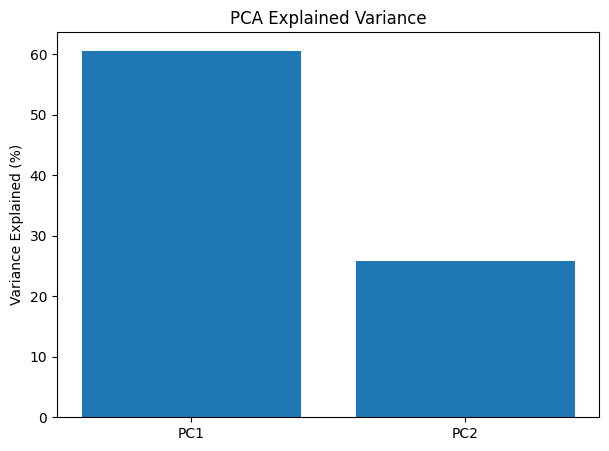

In [ ]:
plt.figure(figsize=(7,5))

plt.bar(
    ['PC1', 'PC2'],
    explained_variance
)

plt.ylabel("Variance Explained (%)")
plt.title("PCA Explained Variance")

plt.show()

Get the loading vectors

In [ ]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=food.columns,
    columns=['PC1', 'PC2']
)

print(loadings.round(4))

             PC1     PC2
Oil       0.4575 -0.3704
Density  -0.4787  0.3567
Crispy    0.5324  0.1977
Fracture -0.5045 -0.2212
Hardness  0.1534  0.8047


PC1 loading plot

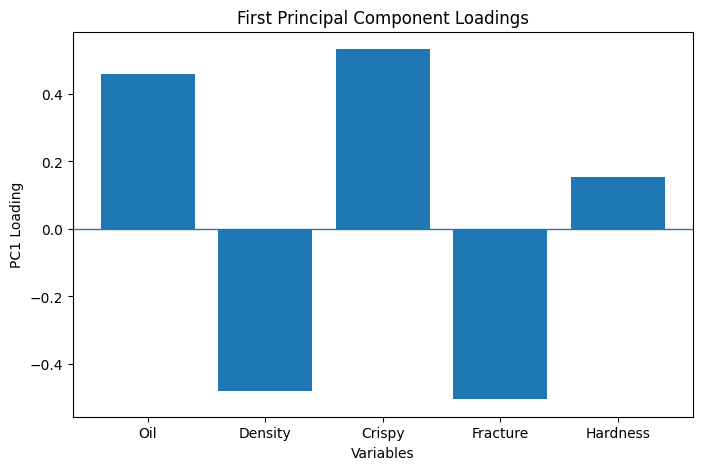

In [ ]:
plt.figure(figsize=(8,5))

plt.bar(
    loadings.index,
    loadings['PC1']
)

plt.axhline(0, linewidth=1)

plt.xlabel("Variables")
plt.ylabel("PC1 Loading")
plt.title("First Principal Component Loadings")

plt.show()

PC2 loading plot

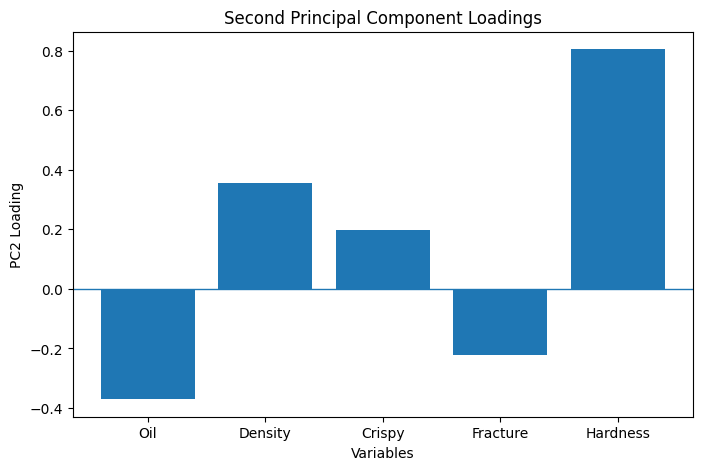

In [ ]:
plt.figure(figsize=(8,5))

plt.bar(
    loadings.index,
    loadings['PC2']
)

plt.axhline(0, linewidth=1)

plt.xlabel("Variables")
plt.ylabel("PC2 Loading")
plt.title("Second Principal Component Loadings")

plt.show()

PC1 vs PC2 score plot

In [ ]:
!pip install -q process-improve

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from process_improve.multivariate import PCA, MCUVScaler

food = pd.read_csv(
    "food-texture.csv",
    index_col=0
)

scaler = MCUVScaler().fit(food)

X_scaled = scaler.transform(food)

model = PCA(n_components=3).fit(X_scaled)

print("PCA model created successfully")
print(model.scores_.head())

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.2/91.2 kB 1.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 46.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 39.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 51.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 2.3.3 which is incompatible.
numba 0.61.2 requires numpy<2.3,>=1.24, but you have numpy 2.5.3 which is incompatible.
PCA model created successfully
             1         2         3
B110 -1.383211 -0.619406 -0.402512
B136  2.794477  0.353725 -1.076027
B171  0.237556  0.861458 -0.611549
B192 -1.939341 -1.141737  0.437947
B225 -1.267937  0.663465  0.437165


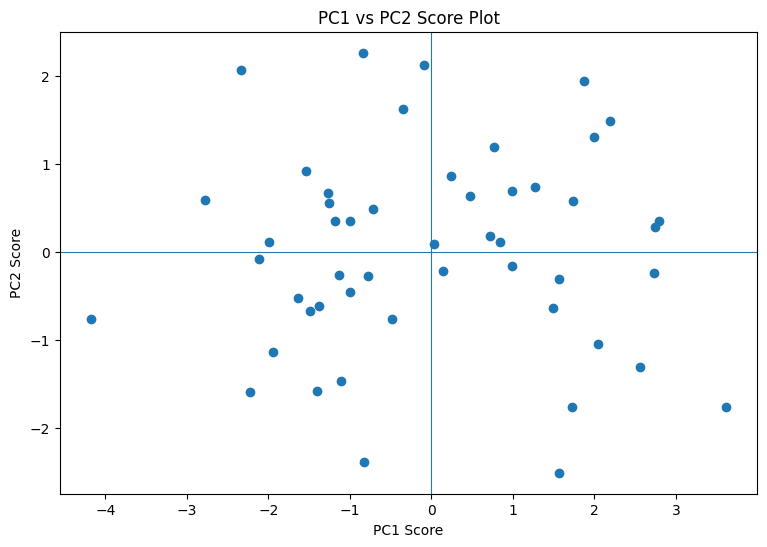

In [ ]:
plt.figure(figsize=(9,6))

plt.scatter(
    model.scores_.iloc[:, 0],
    model.scores_.iloc[:, 1]
)

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.xlabel("PC1 Score")
plt.ylabel("PC2 Score")
plt.title("PC1 vs PC2 Score Plot")

plt.show()

Mark samples 33 and 36

In [ ]:
!pip install -q process-improve

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from process_improve.multivariate import PCA, MCUVScaler

food = pd.read_csv(
    "food-texture.csv",
    index_col=0
)

scaler = MCUVScaler().fit(food)
X_scaled = scaler.transform(food)

model = PCA(n_components=3).fit(X_scaled)

score_df = pd.DataFrame(
    model.scores_.values,
    columns=["PC1", "PC2", "PC3"],
    index=food.index
)

print("PCA model ready.")

PCA model ready.


Sequence plot of PC1 scores

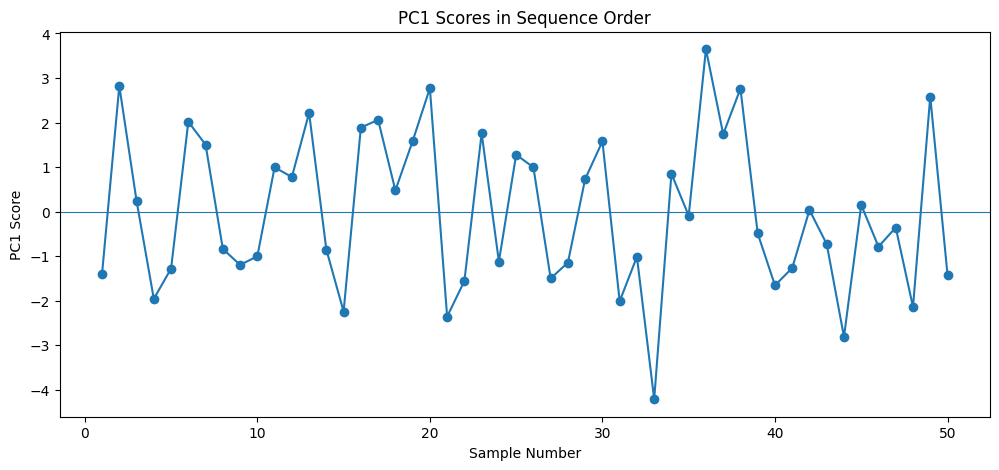

In [ ]:
plt.figure(figsize=(12,5))

plt.plot(
    range(1, len(scores)+1),
    scores[:, 0],
    marker='o'
)

plt.axhline(0, linewidth=0.8)

plt.xlabel("Sample Number")
plt.ylabel("PC1 Score")
plt.title("PC1 Scores in Sequence Order")

plt.show()

Mark samples 33 and 36:

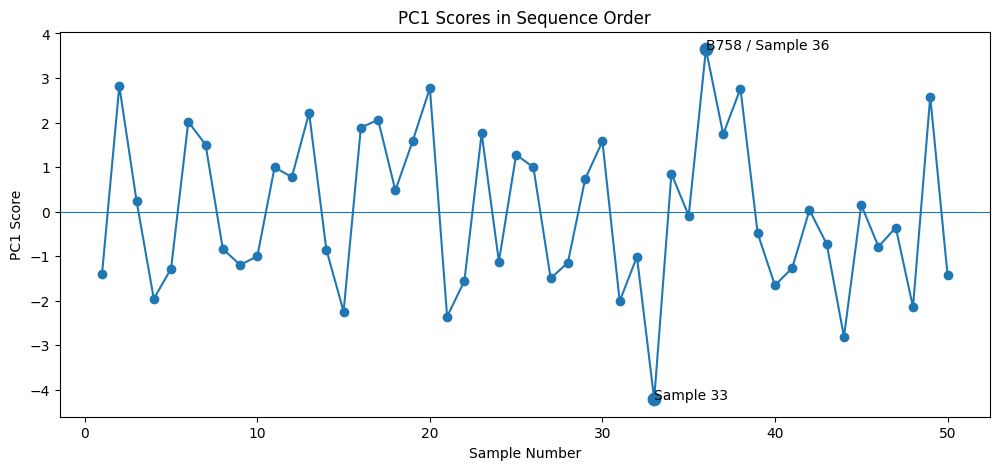

In [ ]:
plt.figure(figsize=(12,5))

plt.plot(
    range(1, len(scores)+1),
    scores[:, 0],
    marker='o'
)

plt.scatter(
    [33, 36],
    [scores[32, 0], scores[35, 0]],
    s=80
)

plt.annotate(
    "Sample 33",
    (33, scores[32, 0])
)

plt.annotate(
    "B758 / Sample 36",
    (36, scores[35, 0])
)

plt.axhline(0, linewidth=0.8)

plt.xlabel("Sample Number")
plt.ylabel("PC1 Score")
plt.title("PC1 Scores in Sequence Order")

plt.show()

Look at the raw data for sample 33


In [ ]:
print(food.iloc[32])

Oil           15.5
Density     3125.0
Crispy         7.0
Fracture      33.0
Hardness      92.0
Name: B694, dtype: float64


Look at B758 / sample 36


In [ ]:
print(food.iloc[35])

Oil           21.2
Density     2570.0
Crispy        14.0
Fracture      13.0
Hardness     105.0
Name: B758, dtype: float64


Plot raw variables in sequence order

This is useful for understanding PC2 as well.



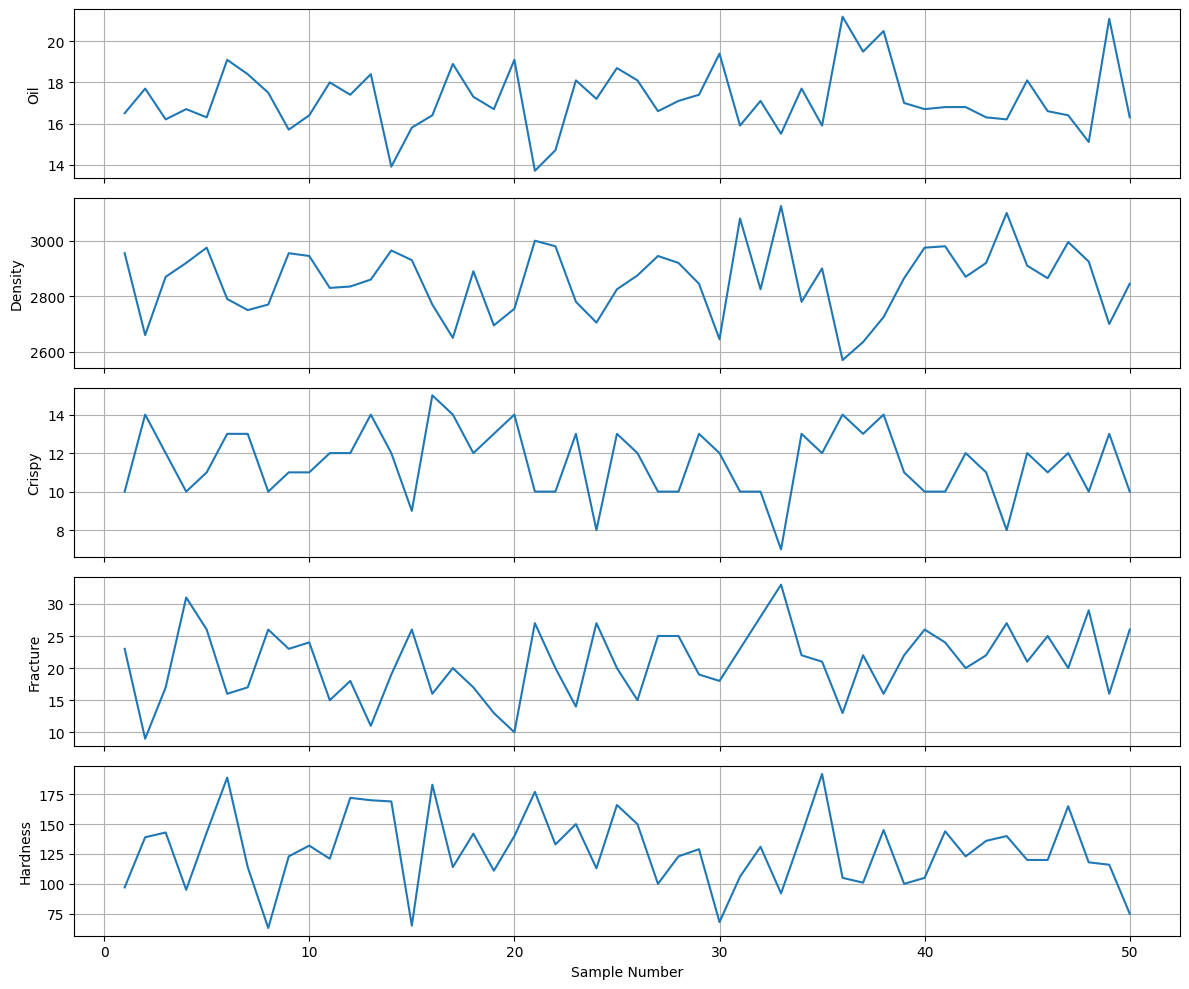

In [ ]:
fig, axes = plt.subplots(
    5, 1,
    figsize=(12, 10),
    sharex=True
)

for i, column in enumerate(food.columns):

    axes[i].plot(
        range(1, len(food)+1),
        food[column]
    )

    axes[i].set_ylabel(column)
    axes[i].grid(True)

axes[-1].set_xlabel("Sample Number")

plt.tight_layout()
plt.show()

PC2 scores


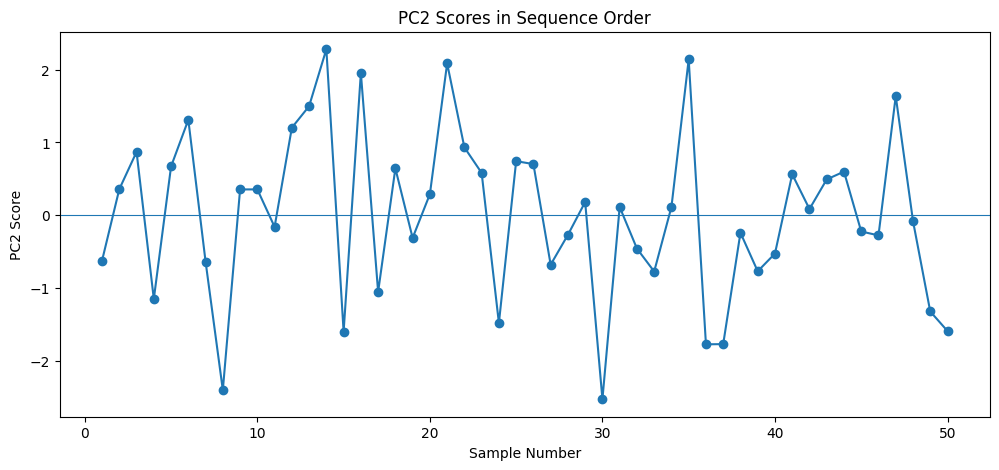

In [ ]:
plt.figure(figsize=(12,5))

plt.plot(
    range(1, len(scores)+1),
    scores[:, 1],
    marker='o'
)

plt.axhline(0, linewidth=0.8)

plt.xlabel("Sample Number")
plt.ylabel("PC2 Score")
plt.title("PC2 Scores in Sequence Order")

plt.show()

Calculate R² per variable

In [ ]:
X_reconstructed = pca.inverse_transform(scores)

total_ss = np.sum(X_scaled**2, axis=0)

residual_ss = np.sum(
    (X_scaled - X_reconstructed)**2,
    axis=0
)

r2_variable = 1 - residual_ss / total_ss

r2_table = pd.DataFrame(
    r2_variable * 100,
    index=food.columns,
    columns=['R² after PC2 (%)']
)

print(r2_table.round(2))

          R² after PC2 (%)
Oil                  81.23
Density              85.97
Crispy               90.98
Fracture             83.49
Hardness             91.03


PC1, PC2 and PC3

In [ ]:
pca3 = PCA(n_components=3)

scores3 = pca3.fit_transform(X_scaled)

explained3 = pca3.explained_variance_ratio_ * 100

print("PC1:", explained3[0])
print("PC2:", explained3[1])
print("PC3:", explained3[2])
print("Total:", explained3.sum())

loadings3 = pd.DataFrame(
    pca3.components_.T,
    index=food.columns,
    columns=['PC1', 'PC2', 'PC3']
)

print(loadings3.round(4))

PC1: 60.62426334584961
PC2: 25.914115275996224
PC3: 6.20098683377477
Total: 92.7393654556206
             PC1     PC2     PC3
Oil       0.4575 -0.3704  0.6590
Density  -0.4787  0.3567  0.0162
Crispy    0.5324  0.1977 -0.1789
Fracture -0.5045 -0.2212  0.5423
Hardness  0.1534  0.8047  0.4892
